# ¿Quién trabaja en la informalidad?
## Un modelo k-NN para focalizar políticas de registración laboral en Argentina

**TP Integrador · Segundo parcial · Python para Ciencia de Datos · UADE**

Integrantes: Marcos López, Joaquín Orozco, Marcos Sada, Matias Zaniboni, Pedro Zanlungo

---

### El problema
En Argentina, más de un tercio de los trabajadores asalariados **no está registrado**: no tiene aportes jubilatorios, obra social, aguinaldo ni vacaciones pagas, ni protección frente a un despido. El Estado tiene herramientas para revertirlo (inspecciones laborales, incentivos a la registración, capacitación), pero los recursos son limitados y no siempre se sabe **a quién priorizar**.

### Pregunta
**¿Podemos predecir si un trabajador asalariado está en la informalidad a partir de sus características personales, laborales y de su hogar?**

### Objetivo
Construir un modelo de **clasificación k-NN** con datos de la Encuesta Permanente de Hogares (EPH) que prediga si un asalariado es **informal** o **formal**, para ayudar a **priorizar** a quién ofrecer programas de registración, capacitación o asesoramiento, y a qué sectores orientar inspecciones.

> El modelo **no** acusa ni sanciona a nadie: estima un riesgo para ordenar prioridades. Tampoco explica causas: encuentra asociaciones.

### Fuente
Microdatos de la **EPH (INDEC)**: base individual y base de hogares, nueve trimestres, del 1T-2024 al 1T-2026.
Descarga: https://www.indec.gob.ar/Institucional/Indec/BasesDeDatos · Diccionario de variables: https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_registro_1T2026.pdf
_Fuente: Instituto Nacional de Estadística y Censos (INDEC)._

### Los ocho pasos
| Paso | Qué hacemos | Herramientas |
|---|---|---|
| 1. Datos | CSV con 9 trimestres unidos (personas + hogares) | `pd.concat`, `pd.merge`, `pd.read_csv` |
| 2. EDA | Univariado y bivariado | histogramas, boxplots, `groupby`, scatterplot, heatmap |
| 3. Calidad | Nulos, duplicados, valores imposibles | `isna`, `duplicated`, criterio de Tukey |
| 4. Split | Separar train y test | `train_test_split(stratify=y)` |
| 5. Modelo | Baseline y k-NN con escalado | `DummyClassifier`, `Pipeline`, `StandardScaler`, `KNeighborsClassifier` |
| 6. Entrenar | Elegir k con validación cruzada | `StratifiedKFold`, `GridSearchCV`, `fit` |
| 7. Predecir | Predicciones sobre test | `predict`, `kneighbors` |
| 8. Evaluar | Métricas | accuracy, matriz de confusión, precision, recall y F1 (`classification_report`) |

# 0. Importar librerías

In [1]:
# Librerías para EDA
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Settings generales para visualizar
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
# Librerías para Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Métricas de clasificación
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [3]:
SEMILLA = 42

---
# 1. Datos

## 1.1 Origen del dataset

La EPH publica, por cada trimestre, dos archivos `.txt` separados por `;`:
- **base individual** (`usu_individual_...`): una fila por **persona**, con más de 230 columnas.
- **base de hogares** (`usu_hogar_...`): una fila por **hogar**, con datos de la vivienda y sus integrantes.

Armamos un único CSV, `eph_2024_2026.csv`, con los **nueve trimestres del 1T-2024 al 1T-2026**, sin ninguna limpieza. Para hacerlo usamos dos herramientas de la U5:

1. **`pd.concat`**: como los nueve trimestres tienen **las mismas columnas**, los apilamos uno debajo del otro (como las dos estaciones meteorológicas).
2. **`pd.merge`**: sumamos tres datos de la base de hogares a cada persona. La clave es **`CODUSU` + `NRO_HOGAR` + `ANO4` + `TRIMESTRE`**. Usamos **left join** porque la unidad de análisis es la **persona** y queremos conservarlas a todas, y `validate="m:1"` para verificar que la relación sea **muchas personas → 1 hogar** (como en la actividad de Airbnb).

Este es el código que generó el CSV (no hace falta volver a correrlo):

```python
trimestres = ["T124", "T224", "T324", "T424", "T125", "T225", "T325", "T425", "T126"]

lista_personas, lista_hogares = [], []
for t in trimestres:
    lista_personas.append(pd.read_csv(f"data/usu_individual_{t}.txt", sep=";", low_memory=False, encoding="latin-1"))
    lista_hogares.append(pd.read_csv(f"data/usu_hogar_{t}.txt", sep=";", low_memory=False, encoding="latin-1"))

personas = pd.concat(lista_personas, axis=0, ignore_index=True)
hogares = pd.concat(lista_hogares, axis=0, ignore_index=True)
personas.columns = personas.columns.str.strip().str.upper()
hogares.columns = hogares.columns.str.strip().str.upper()

columnas = ["CODUSU", "NRO_HOGAR", "COMPONENTE", "ANO4", "TRIMESTRE", "REGION",
            "CH03", "CH04", "CH06", "CH15", "NIVEL_ED", "ESTADO", "CAT_OCUP",
            "PP04A", "PP04B_COD", "PP04C", "PP04C99", "PP07A", "PP3E_TOT", "PP07H"]
clave = ["CODUSU", "NRO_HOGAR", "ANO4", "TRIMESTRE"]

df = pd.merge(personas[columnas], hogares[clave + ["IX_TOT", "IX_MEN10", "II7"]],
              on=clave, how="left", validate="m:1")
df.to_csv("data/eph_2024_2026.csv", index=False)
```

Fuente de los archivos originales: https://www.indec.gob.ar/Institucional/Indec/BasesDeDatos

## 1.2 Las variables

De las más de 230 columnas de la EPH nos quedamos con las que describen a la persona, a su trabajo y a su hogar.

**Dejamos afuera a propósito** las variables que forman parte de la definición de informalidad o que son consecuencia directa de ella (si tiene vacaciones pagas, aguinaldo, obra social, el ingreso). Usarlas sería **darle la respuesta al modelo** (fuga de datos), igual que no podíamos usar el precio para predecir la categoría de precio de los diamantes.

| Código EPH | Variable que construimos | Descripción |
|---|---|---|
| `CODUSU`, `NRO_HOGAR` | — | Identifican al hogar (clave del merge) |
| `COMPONENTE` | — | Número de persona dentro del hogar |
| `ANO4`, `TRIMESTRE` | periodo | Año y trimestre del relevamiento |
| `REGION` | region | GBA, NOA, NEA, Cuyo, Pampeana, Patagonia |
| `CH03` | jefe_hogar | Relación con el jefe/a de hogar |
| `CH04` | mujer | 1 = varón, 2 = mujer |
| `CH06` | edad | Años cumplidos |
| `CH15` | migrante | Dónde nació (esta provincia, otra provincia, otro país) |
| `NIVEL_ED` | nivel_ed | Máximo nivel educativo alcanzado |
| `ESTADO`, `CAT_OCUP` | — | Condición de actividad y categoría ocupacional (para definir el universo) |
| `PP04A` | estatal | Estatal / privado / otro |
| `PP04B_COD` | servicio_domestico, construccion, comercio_gastronomia | Rama de actividad (código CAES) |
| `PP04C`, `PP04C99` | tamano, tamano_sin_dato | Cantidad de personas que trabajan en el lugar |
| `PP07A` | antiguedad | Hace cuánto trabaja en ese empleo |
| `PP3E_TOT` | horas | Horas trabajadas en la semana |
| `IX_TOT` | miembros_hogar | Cantidad de personas en el hogar (base de hogares) |
| `IX_MEN10` | menores_10 | Cantidad de menores de 10 años en el hogar (base de hogares) |
| `II7` | propietario | Régimen de tenencia de la vivienda: 1 y 2 = propietario (base de hogares) |
| **`PP07H`** | **informal (y)** | **¿Por ese trabajo tiene descuento jubilatorio? 1 = sí, 2 = no** |

## 1.3 Cargar el CSV

In [4]:
# CSV unificado (9 trimestres, personas + hogares)
# Se lee de la carpeta data/ del repositorio; si no está, se descarga de Google Drive
import os

file_id = "1bC3oNIHW-I7LqynUj190ND8TDwSl2sF6"
ruta_local = "data/eph_2024_2026.csv"
archivos = ruta_local if os.path.exists(ruta_local) else f"https://drive.google.com/uc?export=download&id={file_id}"
df = pd.read_csv(archivos)
print(f"Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.head()

Dataset: 411,524 filas x 23 columnas


,CODUSU,NRO_HOGAR,COMPONENTE,ANO4,TRIMESTRE,REGION,CH03,CH04,CH06,CH15,...,PP04A,PP04B_COD,PP04C,PP04C99,PP07A,PP3E_TOT,PP07H,IX_TOT,IX_MEN10,II7
0,TQRMNOSTSHJOLOCDEHLEH00795168,1,1,2024,1,40,1,2,86,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,1
1,TQRMNOSQYHJMLPCDEIKAH00793199,1,1,2024,1,43,1,1,68,3,...,2.00,4000.00,1.00,0.00,0.00,6.00,0.00,2,0,1
2,TQRMNOSQYHJMLPCDEIKAH00793199,1,2,2024,1,43,3,1,20,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0,1
3,TQRMNORWPHJOLLCDEGPDJ00795996,1,1,2024,1,40,1,2,75,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,1
4,TQRMNOTQRHJMLOCDEHJGH00794657,1,1,2024,1,40,1,2,41,1,...,2.00,9602.00,1.00,0.00,0.00,12.00,0.00,4,0,1


In [5]:
# Cantidad de personas encuestadas por trimestre
df.groupby(["ANO4", "TRIMESTRE"], as_index=False)["CODUSU"].count()

,ANO4,TRIMESTRE,CODUSU
0,2024,1,46050
1,2024,2,47151
2,2024,3,47564
3,2024,4,46860
4,2025,1,45425
5,2025,2,46086
6,2025,3,44946
7,2025,4,43703
8,2026,1,43739


---
# 2. Calidad de los datos

Revisamos tipos de datos, nulos, duplicados y valores imposibles. En cada caso explicamos **qué decidimos y por qué**.

## 2.1 Tipos de datos

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 411524 entries, 0 to 411523
Data columns (total 23 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   CODUSU      411524 non-null  str    
 1   NRO_HOGAR   411524 non-null  int64  
 2   COMPONENTE  411524 non-null  int64  
 3   ANO4        411524 non-null  int64  
 4   TRIMESTRE   411524 non-null  int64  
 5   REGION      411524 non-null  int64  
 6   CH03        411524 non-null  int64  
 7   CH04        411524 non-null  int64  
 8   CH06        411524 non-null  int64  
 9   CH15        411524 non-null  int64  
 10  NIVEL_ED    411524 non-null  int64  
 11  ESTADO      411524 non-null  int64  
 12  CAT_OCUP    411524 non-null  int64  
 13  PP04A       183010 non-null  float64
 14  PP04B_COD   183010 non-null  float64
 15  PP04C       183010 non-null  float64
 16  PP04C99     183010 non-null  float64
 17  PP07A       183010 non-null  float64
 18  PP3E_TOT    183010 non-null  float64
 19  PP07H       1

Todo viene como número, pero **la mayoría son códigos de categorías** (por ejemplo `REGION = 43` es Pampeana y `CH04 = 2` es mujer). Las columnas del trabajo (`PP...`) vienen como `float` porque tienen nulos. Más adelante convertimos cada código en una variable que tenga sentido.

## 2.2 Nulos

In [7]:
nulos = df.isna().sum().to_frame("nulos")
nulos["%"] = (nulos["nulos"] / len(df) * 100).round(1)
nulos[nulos["nulos"] > 0]

,nulos,%
PP04A,228514,55.50
PP04B_COD,228514,55.50
PP04C,228514,55.50
PP04C99,228514,55.50
PP07A,228514,55.50
PP3E_TOT,228514,55.50
PP07H,228514,55.50


In [8]:
# ¿Los nulos de las variables laborales coinciden con las personas que no trabajan?
print("Personas no ocupadas (ESTADO distinto de 1):", (df["ESTADO"] != 1).sum())
print("Nulos en PP07H:                             ", df["PP07H"].isna().sum())

Personas no ocupadas (ESTADO distinto de 1): 228514
Nulos en PP07H:                              228514


Los nulos de las columnas del trabajo **no son datos perdidos**: son exactamente las personas que no están ocupadas (desocupados, inactivos, menores), a quienes no se les hacen esas preguntas. Se resuelven solos al definir el universo de análisis.

## 2.3 Universo de análisis: asalariados

La pregunta sobre descuento jubilatorio (`PP07H`) solo se hace a los **asalariados**. Nos quedamos con personas ocupadas (`ESTADO = 1`) que son obreros o empleados (`CAT_OCUP = 3`).

In [9]:
filas_antes = len(df)
df = df[(df["ESTADO"] == 1) & (df["CAT_OCUP"] == 3)].copy()
print(f"Asalariados: {len(df):,} de {filas_antes:,} filas ({len(df) / filas_antes:.0%})")

Asalariados: 132,734 de 411,524 filas (32%)


## 2.4 Duplicados

In [10]:
df["id_persona"] = df["CODUSU"] + "_" + df["NRO_HOGAR"].astype(str) + "_" + df["COMPONENTE"].astype(str)

print("Filas duplicadas completas:            ", df.duplicated().sum())
print("Persona repetida en el mismo trimestre:", df.duplicated(["id_persona", "ANO4", "TRIMESTRE"]).sum())
print("Persona repetida entre trimestres:     ", df.duplicated("id_persona").sum())

Filas duplicadas completas:             0
Persona repetida en el mismo trimestre: 0
Persona repetida entre trimestres:      61367


No hay filas duplicadas ni personas repetidas dentro de un mismo trimestre. Pero **muchas personas aparecen en varios trimestres**: la EPH es un *panel rotativo* (un hogar se encuesta dos trimestres seguidos, sale dos y vuelve a entrar otros dos).

Para el **EDA y la serie de tiempo** las conservamos: en cada trimestre esa persona forma parte de la muestra.

Para el **modelo** nos quedamos con **una sola fila por persona** (la más reciente). Si la misma persona quedara a la vez en train y en test, el modelo "la reconocería" y el resultado sería demasiado optimista. Lo hacemos en el paso 4, antes del split.

## 2.5 Valores imposibles y códigos especiales

La EPH usa códigos numéricos para "no sabe / no responde". Si no los tratamos, el modelo creería, por ejemplo, que alguien trabaja 999 horas por semana.

In [11]:
problemas = pd.DataFrame({
    "PP07H (y) sin respuesta (0 o 9)":           (~df["PP07H"].isin([1, 2])).sum(),
    "CH06 edad menor a 14":                       (df["CH06"] < 14).sum(),
    "PP3E_TOT horas = 999 (no responde)":         (df["PP3E_TOT"] == 999).sum(),
    "PP3E_TOT horas entre 99 y 998 (imposible)":  df["PP3E_TOT"].between(99, 998).sum(),
    "PP04C tamaño = 0 o 99 (no sabe)":            df["PP04C"].isin([0, 99]).sum(),
    "  ... y PP04C99 tampoco lo sabe":            (df["PP04C"].isin([0, 99]) & df["PP04C99"].isin([0, 9])).sum(),
    "PP07A antigüedad = 0 o 9 (sin dato)":        df["PP07A"].isin([0, 9]).sum(),
    "PP04B_COD rama sin código":                  df["PP04B_COD"].isna().sum(),
    "CH15 nacimiento = 9 (no sabe)":              (df["CH15"] == 9).sum(),
}, index=["casos"]).T
problemas["% de asalariados"] = (problemas["casos"] / len(df) * 100).round(2)
problemas

,casos,% de asalariados
PP07H (y) sin respuesta (0 o 9),0,0.00
CH06 edad menor a 14,15,0.01
PP3E_TOT horas = 999 (no responde),191,0.14
PP3E_TOT horas entre 99 y 998 (imposible),130,0.10
PP04C tamaño = 0 o 99 (no sabe),36292,27.34
... y PP04C99 tampoco lo sabe,22641,17.06
PP07A antigüedad = 0 o 9 (sin dato),13434,10.12
PP04B_COD rama sin código,0,0.00
CH15 nacimiento = 9 (no sabe),34,0.03


Para las horas trabajadas, además, aplicamos el **criterio de Tukey** que vimos en la U4 para ver qué valores son atípicos:

In [12]:
horas_validas = df.loc[df["PP3E_TOT"] < 999, "PP3E_TOT"]

Q1 = horas_validas.quantile(0.25)
Q3 = horas_validas.quantile(0.75)
RIC = Q3 - Q1
limite_inf = Q1 - 1.5 * RIC
limite_sup = Q3 + 1.5 * RIC

print(f"Q1 = {Q1:.0f} h | Q3 = {Q3:.0f} h | RIC = {RIC:.0f} h")
print(f"Límites de Tukey: {limite_inf:.0f} h a {limite_sup:.0f} h")
print(f"Outliers según Tukey: {((horas_validas < limite_inf) | (horas_validas > limite_sup)).sum():,}")

Q1 = 24 h | Q3 = 45 h | RIC = 21 h
Límites de Tukey: -8 h a 76 h
Outliers según Tukey: 1,408


**Decisiones:**

- **Variable objetivo sin respuesta (`PP07H` = 0 o 9):** habría que eliminar esas filas, porque no se puede entrenar ni evaluar sin la respuesta correcta. En estos trimestres no hay ninguna.
- **Edad menor a 14:** eliminamos esos pocos casos. El trabajo infantil es un problema distinto, fuera del alcance de este modelo.
- **Horas = 999 o mayores a 98:** las pasamos a nulo. 999 es el código de "no responde" y más de 98 horas semanales (14 horas por día, los 7 días) no es creíble.
- **Outliers de Tukey en horas:** Tukey marca como atípicas las jornadas muy cortas o muy largas, pero son **valores posibles** (changas de pocas horas, doble turno). Atípico no es lo mismo que imposible, por eso **no los eliminamos**.
- **Tamaño del establecimiento:** cuando la persona no sabe el número exacto (`PP04C` = 0 o 99) usamos la pregunta de respaldo `PP04C99`, que pregunta por rangos. Si tampoco sabe, queda como **"sin dato"**. Son muchos casos, así que no los borramos: creamos una variable que indica que no hay dato (ver 2.6).
- **Antigüedad sin dato:** también son muchos casos. Los completamos con la **mediana de train** después del split (paso 4), para no usar información de test.
- **Rama sin código, horas y nacimiento sin dato:** son pocos casos (menos del 1 %). Los eliminamos con `dropna`.

## 2.6 Transformar los códigos en variables

KNN calcula **distancias**, así que necesita números. Seguimos dos reglas, igual que con el corte de los diamantes en la U7:

- **Variables con orden** (nivel educativo, tamaño del establecimiento, antigüedad): las pasamos a números que respeten ese orden con `.map()`.
- **Variables sin orden** (sexo, sector, rama...): las convertimos en variables **0/1** que responden una pregunta, como hicimos con `es_local` o `verificado` en Airbnb. Por ejemplo `mujer` = 1 si es mujer.

Para la **rama de actividad** (16 ramas, sin orden) armamos variables 0/1 para las ramas con más informalidad según los informes del INDEC y lo que muestra el EDA: servicio doméstico, construcción y comercio/gastronomía.

In [13]:
# --- Filtros de calidad ---
df = df[df["PP07H"].isin([1, 2]) & (df["CH06"] >= 14)].copy()

# --- Variable objetivo: 1 = informal (sin descuento jubilatorio), 0 = formal ---
df["informal"] = (df["PP07H"] == 2).astype(int)

# --- Fecha del trimestre (para la serie de tiempo) ---
df["periodo"] = df["ANO4"].astype(str) + "-T" + df["TRIMESTRE"].astype(str)

# --- Numéricas ---
df["edad"] = df["CH06"]
df["horas"] = df["PP3E_TOT"].where(df["PP3E_TOT"] <= 98)          # 999 y > 98 -> nulo
df["miembros_hogar"] = df["IX_TOT"]
df["menores_10"] = df["IX_MEN10"]

# --- Ordinales con .map() ---
# Nivel educativo: el código 7 de la EPH es "sin instrucción", lo pasamos a 0
df["nivel_ed"] = df["NIVEL_ED"].map({7: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6})
# Antigüedad: 1 = menos de 1 mes ... 6 = más de 5 años (0 y 9 quedan como nulo)
df["antiguedad"] = df["PP07A"].map({1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6})

# Tamaño del establecimiento: 1 = hasta 5 personas, 2 = de 6 a 40, 3 = más de 40
df["tamano"] = df["PP04C"].map({1: 1, 2: 1, 3: 1, 4: 1, 5: 1,
                                6: 2, 7: 2, 8: 2,
                                9: 3, 10: 3, 11: 3, 12: 3})
# Si no sabe el número exacto, usamos la pregunta de respaldo por rangos (PP04C99)
df["tamano"] = df["tamano"].fillna(df["PP04C99"].map({1: 1, 2: 2, 3: 3}))
df["tamano_sin_dato"] = df["tamano"].isna().astype(int)
df["tamano"] = df["tamano"].fillna(0).astype(int)   # 0 = sin dato (lo marca la columna tamano_sin_dato)

# --- Binarias 0/1 ---
df["mujer"] = (df["CH04"] == 2).astype(int)
df["jefe_hogar"] = (df["CH03"] == 1).astype(int)
df["estatal"] = (df["PP04A"] == 1).astype(int)
df["migrante"] = df["CH15"].isin([4, 5]).astype(int)                 # nació en otro país
df["propietario"] = df["II7"].isin([1, 2]).astype(int)               # propietario de la vivienda

# Rama: los dos primeros dígitos del código CAES indican la división de actividad
division = df["PP04B_COD"] // 100
df["servicio_domestico"] = (division == 97).astype(int)
df["construccion"] = division.between(40, 43).astype(int)
df["comercio_gastronomia"] = (division.between(45, 48) | division.between(55, 56)).astype(int)

# --- Etiquetas legibles (solo para el EDA) ---
df["region"] = df["REGION"].map({1: "GBA", 40: "NOA", 41: "NEA", 42: "Cuyo", 43: "Pampeana", 44: "Patagonia"})
df["condicion"] = df["informal"].map({0: "Formal", 1: "Informal"})
df["sexo"] = df["mujer"].map({0: "Varón", 1: "Mujer"})

# --- Eliminamos los pocos casos sin rama, horas o lugar de nacimiento ---
df = df[df["PP04B_COD"].notna() & df["horas"].notna() & (df["CH15"] != 9)].copy()

print(f"Asalariados después de la limpieza: {len(df):,}")

Asalariados después de la limpieza: 132,368


In [14]:
NUMERICAS = ["edad", "horas", "antiguedad", "nivel_ed", "tamano", "miembros_hogar", "menores_10"]
BINARIAS = ["tamano_sin_dato", "mujer", "jefe_hogar", "estatal", "migrante", "propietario",
            "servicio_domestico", "construccion", "comercio_gastronomia"]
VARIABLES = NUMERICAS + BINARIAS          # todas: las usamos en el EDA
HOGAR = ["miembros_hogar", "menores_10", "propietario"]
VARIABLES_MODELO = [v for v in VARIABLES if v not in HOGAR]   # las que entran al modelo (ver paso 5.2)

datos = df[["id_persona", "ANO4", "TRIMESTRE", "periodo", "region", "sexo", "condicion"] + VARIABLES + ["informal"]]
datos = datos.reset_index(drop=True)
print(f"Dataset limpio: {datos.shape[0]:,} filas x {datos.shape[1]} columnas")
print("\nNulos que quedan:")
print(datos.isna().sum()[datos.isna().sum() > 0])
datos.head()

Dataset limpio: 132,368 filas x 24 columnas

Nulos que quedan:
antiguedad    13315
dtype: int64


,id_persona,ANO4,TRIMESTRE,periodo,region,sexo,condicion,edad,horas,antiguedad,...,tamano_sin_dato,mujer,jefe_hogar,estatal,migrante,propietario,servicio_domestico,construccion,comercio_gastronomia,informal
0,TQRMNOTQRHJMLOCDEHJGH00794657_1_2,2024,1,2024-T1,NOA,Varón,Formal,42,48.00,6.00,...,0,0,0,0,0,1,0,0,1,0
1,TQRMNORWQHJMKPCDEIKAH00794680_1_1,2024,1,2024-T1,Pampeana,Varón,Formal,29,48.00,6.00,...,0,0,1,1,0,1,0,0,0,0
2,TQRMNORXSHJMLQCDEGPDJ00794708_1_3,2024,1,2024-T1,NOA,Varón,Formal,33,44.00,5.00,...,0,0,0,0,0,1,0,0,1,0
3,TQRMNOQYUHJLKQCDEHLEH00794723_1_1,2024,1,2024-T1,NOA,Varón,Formal,61,40.00,6.00,...,0,0,1,0,0,1,0,0,0,0
4,TQRMNOQYUHJLKQCDEHLEH00794723_1_3,2024,1,2024-T1,NOA,Varón,Formal,25,30.00,5.00,...,0,0,0,0,0,1,0,0,0,0


Solo queda con nulos la **antigüedad**, que completamos después del split. Guardamos la versión limpia en un CSV.

In [15]:
datos.to_csv("data/eph_asalariados_limpio.csv", index=False)

---
# 3. EDA univariado

> **Nota:** la EPH trae un ponderador (`PONDERA`) para estimar valores de toda la población. Acá trabajamos con **proporciones simples de la muestra**; los resultados son muy parecidos a los oficiales.

## 3.1 Variable objetivo

In [16]:
print(datos["condicion"].value_counts())
print()
print(datos["condicion"].value_counts(normalize=True).round(3))

condicion
Formal      83629
Informal    48739
Name: count, dtype: int64

condicion
Formal     0.63
Informal   0.37
Name: proportion, dtype: float64


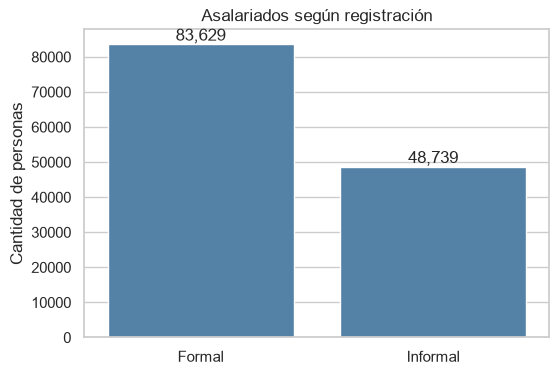

In [17]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=datos, x="condicion", order=["Formal", "Informal"], color="steelblue")
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.title("Asalariados según registración")
plt.xlabel("")
plt.ylabel("Cantidad de personas")
plt.show()

Alrededor de **un tercio** de los asalariados no tiene descuento jubilatorio. Las clases están **desbalanceadas**: un modelo que diga siempre "formal" ya acertaría en la mayoría de los casos. Por eso lo vamos a comparar contra ese **baseline**.

## 3.2 Variables numéricas: medidas de resumen

In [18]:
datos[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,132368.00,40.16,12.51,14.00,30.00,39.00,49.00,100.00
horas,132368.00,34.66,16.24,0.00,24.00,40.00,45.00,98.00
antiguedad,119053.00,5.19,1.19,1.00,5.00,6.00,6.00,6.00
nivel_ed,132368.00,4.24,1.36,0.00,3.00,4.00,6.00,6.00
tamano,132368.00,1.79,1.07,0.00,1.00,2.00,3.00,3.00
miembros_hogar,132368.00,3.58,1.79,1.00,2.00,3.00,4.00,19.00
menores_10,132368.00,0.42,0.73,0.00,0.00,0.00,1.00,7.00


Usamos la función `plot_histograma_full` de la U4, que marca la media y la mediana.

In [19]:
def plot_histograma_full(df, variable, desvio=False, bins="auto"):

    sns.histplot(
        data=df,
        x=variable,
        bins=bins,
        kde=True
    )

    # Media - mediana - desvio
    media = df[variable].mean()
    mediana = df[variable].median()
    std = df[variable].std()

    plt.axvline(media, linestyle="-", color="red", label=f"Media: {media:.2f}")
    plt.axvline(mediana, linestyle="--", color="orange", label=f"Mediana: {mediana:.2f}")

    if desvio:
        plt.axvline(media + std, linestyle="--", color="green", label=f"+1std: {media + std:.2f}")
        plt.axvline(media - std, linestyle="--", color="green", label=f"-1std: {media - std:.2f}")

    plt.title(f"Distribución de {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")
    plt.legend()

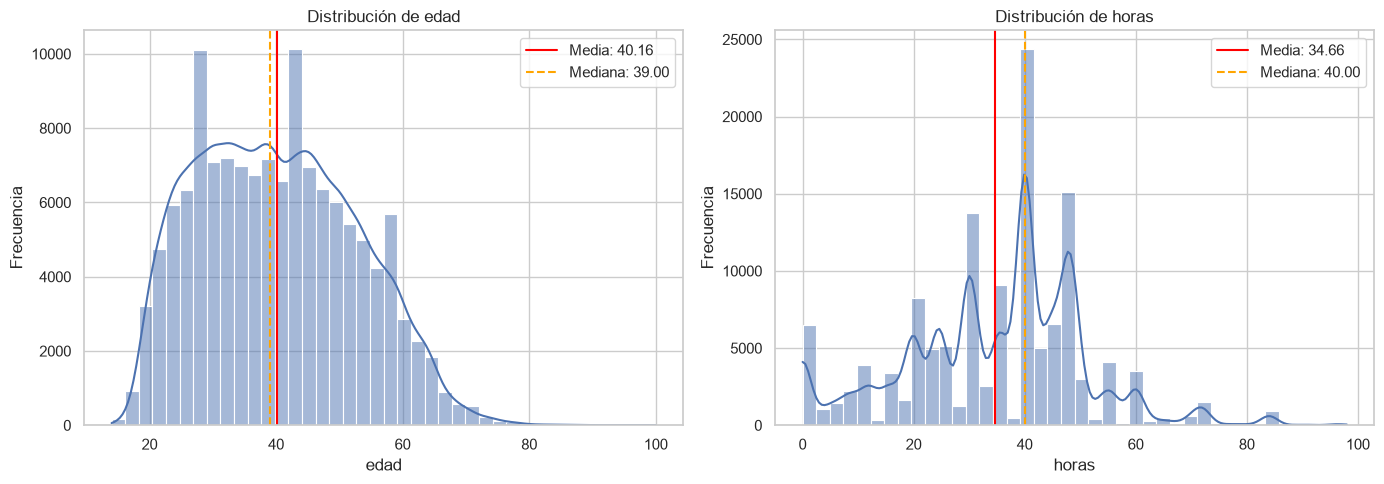

In [20]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plot_histograma_full(datos, "edad", bins=40)

plt.subplot(1, 2, 2)
plot_histograma_full(datos, "horas", bins=40)

plt.tight_layout()
plt.show()

- **Edad:** la media y la mediana son casi iguales (alrededor de 40 años), la distribución es bastante simétrica. Hay pocos menores de 20 y mayores de 65.
- **Horas:** la mediana (40 h) es mayor que la media: hay una cola hacia la izquierda de **jornadas parciales**. Se ven picos en valores "redondos" (20, 30, 40, 48 h), típico de datos declarados por los encuestados.

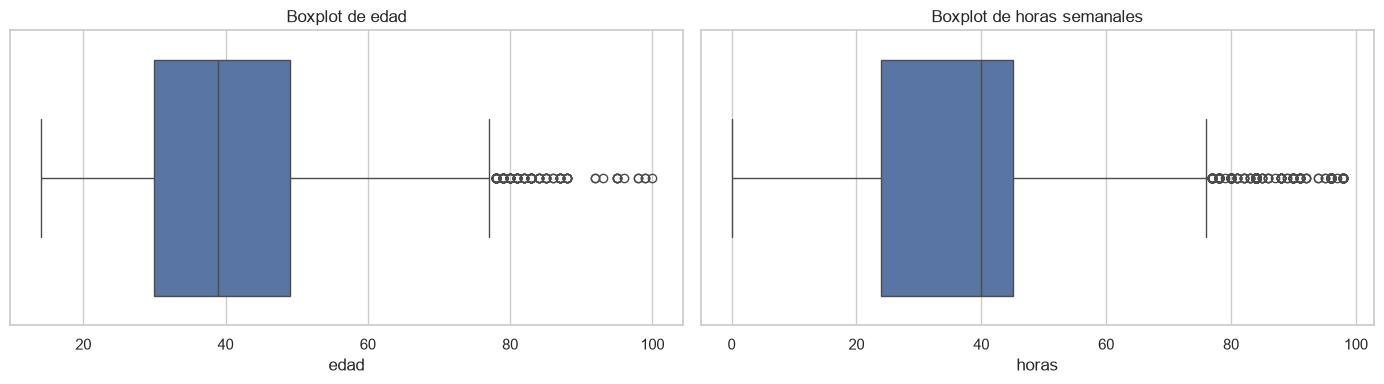

In [21]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.boxplot(data=datos, x="edad")
plt.title("Boxplot de edad")

plt.subplot(1, 2, 2)
sns.boxplot(data=datos, x="horas")
plt.title("Boxplot de horas semanales")

plt.tight_layout()
plt.show()

El boxplot de horas muestra muchos outliers de los dos lados (lo que vimos con Tukey en el paso 2): jornadas muy cortas y muy largas, que son posibles y por eso los conservamos.

## 3.3 Variables ordinales y binarias: frecuencias

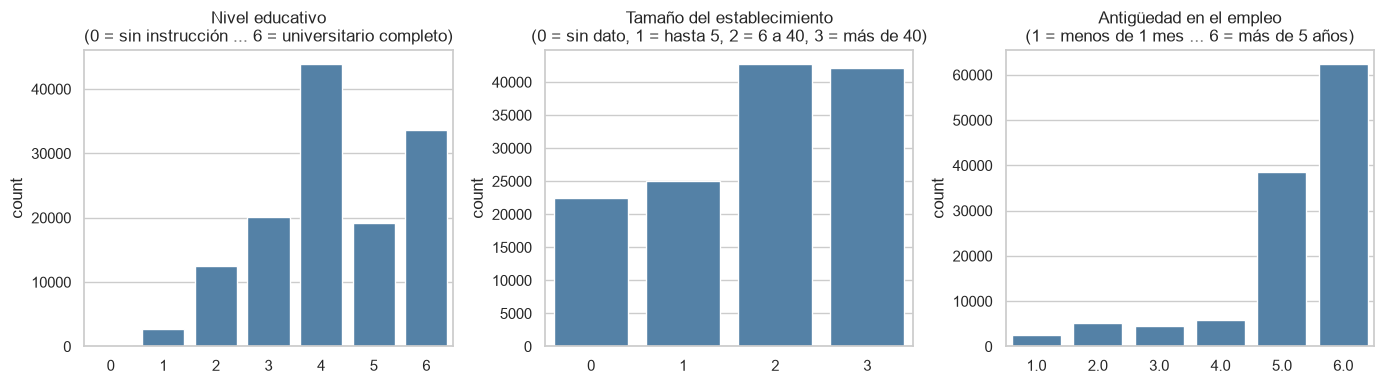

In [22]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
sns.countplot(data=datos, x="nivel_ed", color="steelblue")
plt.title("Nivel educativo\n(0 = sin instrucción ... 6 = universitario completo)")
plt.xlabel("")

plt.subplot(1, 3, 2)
sns.countplot(data=datos, x="tamano", color="steelblue")
plt.title("Tamaño del establecimiento\n(0 = sin dato, 1 = hasta 5, 2 = 6 a 40, 3 = más de 40)")
plt.xlabel("")

plt.subplot(1, 3, 3)
sns.countplot(data=datos, x="antiguedad", color="steelblue")
plt.title("Antigüedad en el empleo\n(1 = menos de 1 mes ... 6 = más de 5 años)")
plt.xlabel("")

plt.tight_layout()
plt.show()

In [23]:
# Porcentaje de personas con cada característica binaria (la media de una variable 0/1 es una proporción)
(datos[BINARIAS].mean() * 100).sort_values(ascending=False).round(1).to_frame("% con valor 1")

,% con valor 1
propietario,68.00
jefe_hogar,47.80
mujer,46.80
estatal,29.30
comercio_gastronomia,19.50
tamano_sin_dato,17.00
servicio_domestico,9.50
construccion,7.30
migrante,2.80


- **Nivel educativo:** la moda es secundario completo (4), seguida de universitario completo (6).
- **Antigüedad:** la mayoría tiene más de 5 años en su empleo.
- Casi un tercio trabaja en el **Estado**, y alrededor de 1 de cada 10 en **servicio doméstico**.

---
# 4. EDA bivariado: ¿qué se relaciona con la informalidad?

## 4.1 Tasa de informalidad por grupo (`groupby` + `agg`)

Como `informal` vale 0 o 1, **su promedio es la proporción de informales** del grupo.

In [24]:
def tasa_por(variable):
    tabla = (
        datos.groupby(variable, as_index=False)
        .agg(personas=("informal", "count"),
             tasa_informal=("informal", "mean"))
    )
    tabla["tasa_informal"] = (tabla["tasa_informal"] * 100).round(1)
    return tabla

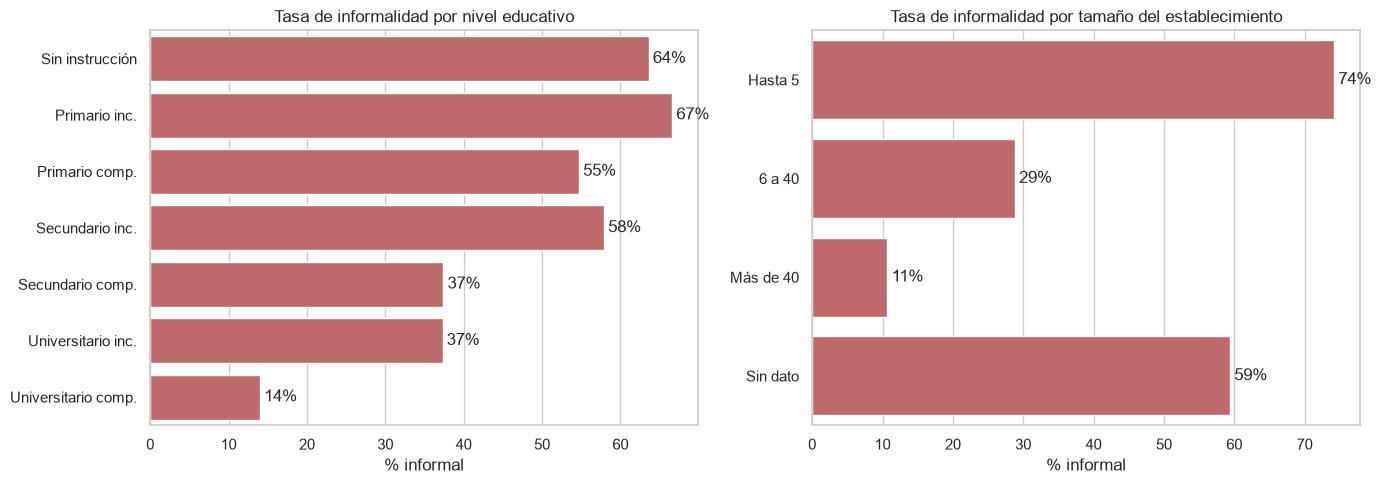

In [25]:
# Nivel educativo y tamaño del establecimiento
nombres_ed = {0: "Sin instrucción", 1: "Primario inc.", 2: "Primario comp.", 3: "Secundario inc.",
              4: "Secundario comp.", 5: "Universitario inc.", 6: "Universitario comp."}
nombres_tam = {0: "Sin dato", 1: "Hasta 5", 2: "6 a 40", 3: "Más de 40"}

tasa_ed = tasa_por("nivel_ed")
tasa_ed["nivel_ed"] = tasa_ed["nivel_ed"].map(nombres_ed)
tasa_tam = tasa_por("tamano")
tasa_tam["tamano"] = tasa_tam["tamano"].map(nombres_tam)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
ax = sns.barplot(data=tasa_ed, x="tasa_informal", y="nivel_ed", color="indianred")
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
plt.title("Tasa de informalidad por nivel educativo")
plt.xlabel("% informal")
plt.ylabel("")

plt.subplot(1, 2, 2)
ax = sns.barplot(data=tasa_tam, x="tasa_informal", y="tamano", color="indianred",
                 order=["Hasta 5", "6 a 40", "Más de 40", "Sin dato"])
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
plt.title("Tasa de informalidad por tamaño del establecimiento")
plt.xlabel("% informal")
plt.ylabel("")

plt.tight_layout()
plt.show()

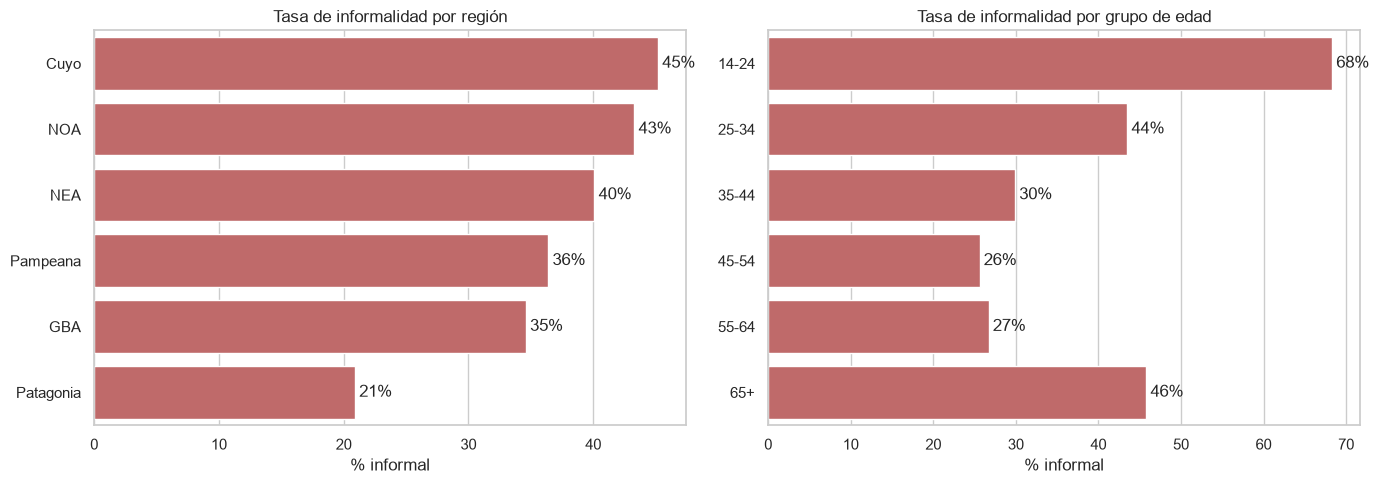

In [26]:
# Región y grupo de edad (pd.cut convierte la edad en rangos, como en la actividad de Airbnb)
datos["grupo_edad"] = pd.cut(datos["edad"], bins=[13, 24, 34, 44, 54, 64, 120],
                             labels=["14-24", "25-34", "35-44", "45-54", "55-64", "65+"])

tasa_region = tasa_por("region").sort_values("tasa_informal", ascending=False)
tasa_edad = tasa_por("grupo_edad")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
ax = sns.barplot(data=tasa_region, x="tasa_informal", y="region", color="indianred")
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
plt.title("Tasa de informalidad por región")
plt.xlabel("% informal")
plt.ylabel("")

plt.subplot(1, 2, 2)
ax = sns.barplot(data=tasa_edad, x="tasa_informal", y="grupo_edad", color="indianred")
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
plt.title("Tasa de informalidad por grupo de edad")
plt.xlabel("% informal")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [27]:
# Variables binarias: tasa de informalidad cuando la variable vale 0 y cuando vale 1
filas = []
for v in BINARIAS:
    filas.append({"variable": v,
                  "tasa si = 0": datos.loc[datos[v] == 0, "informal"].mean() * 100,
                  "tasa si = 1": datos.loc[datos[v] == 1, "informal"].mean() * 100})
tabla_binarias = pd.DataFrame(filas).round(1)
tabla_binarias["diferencia"] = tabla_binarias["tasa si = 1"] - tabla_binarias["tasa si = 0"]
tabla_binarias.sort_values("diferencia", ascending=False)

,variable,tasa si = 0,tasa si = 1,diferencia
6,servicio_domestico,32.50,78.00,45.50
7,construccion,34.20,69.40,35.20
0,tamano_sin_dato,32.20,59.40,27.20
8,comercio_gastronomia,33.90,48.90,15.00
4,migrante,36.60,44.30,7.70
1,mujer,35.30,38.60,3.30
5,propietario,34.60,37.90,3.30
2,jefe_hogar,43.80,29.20,-14.60
3,estatal,47.50,11.00,-36.50


**Lo que muestran los gráficos y la tabla:**

- **Educación:** la informalidad es muy alta hasta secundario incompleto y **baja fuerte al terminar el secundario**; con universitario completo es la más baja.
- **Tamaño del establecimiento:** es la diferencia más grande. En lugares de hasta 5 personas la informalidad es varias veces mayor que en los de más de 40. Además, **no saber el tamaño** es muy común entre los informales (changas, trabajo en casas particulares).
- **Región:** el norte y Cuyo tienen más informalidad; la Patagonia, la menor.
- **Edad:** forma de "U": los más jóvenes y los mayores de 65 son los más informales.
- **Variables binarias:** trabajar en **servicio doméstico** o en la **construcción** dispara la informalidad; trabajar en el **Estado** la reduce mucho.

## 4.2 Variables numéricas según la condición

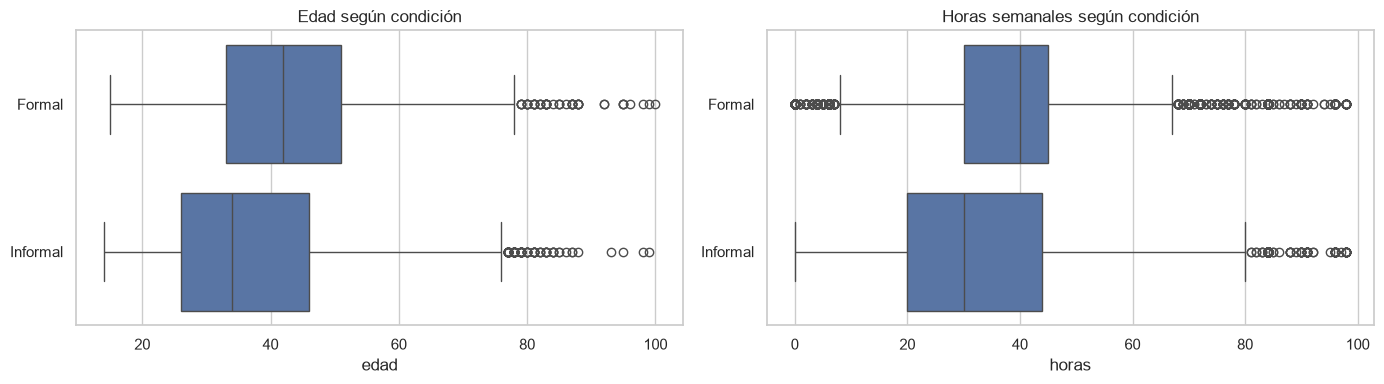

,edad,horas,antiguedad,nivel_ed
condicion,,,,
Formal,42.00,40.00,6.00,4.00
Informal,34.00,30.00,5.00,4.00


In [28]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.boxplot(data=datos, x="edad", y="condicion", order=["Formal", "Informal"])
plt.title("Edad según condición")
plt.ylabel("")

plt.subplot(1, 2, 2)
sns.boxplot(data=datos, x="horas", y="condicion", order=["Formal", "Informal"])
plt.title("Horas semanales según condición")
plt.ylabel("")

plt.tight_layout()
plt.show()

datos.groupby("condicion")[["edad", "horas", "antiguedad", "nivel_ed"]].median()

Los informales son, en mediana, **más jóvenes**, trabajan **menos horas** y tienen **menos antigüedad**. La mediana del nivel educativo es la misma en los dos grupos (secundario completo), pero, como vimos en 4.1, la tasa de informalidad baja mucho a medida que sube la educación.

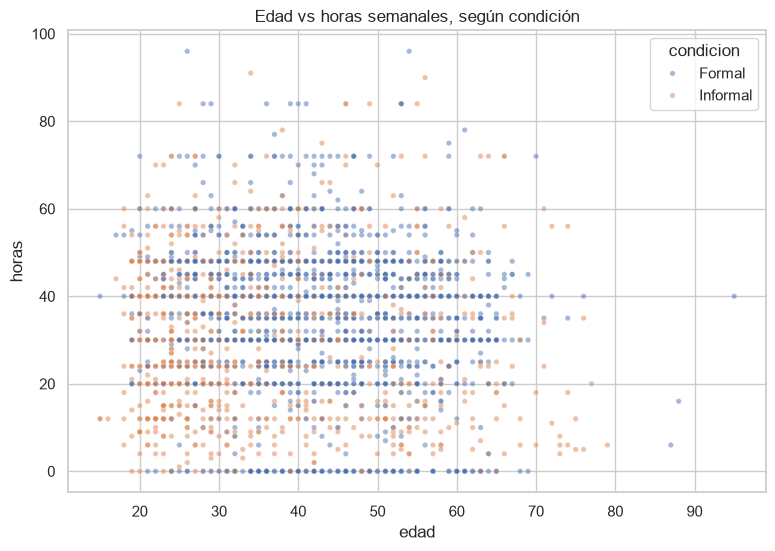

In [29]:
# Scatterplot edad vs horas (muestra de 3.000 personas para que se vea)
muestra = datos.sample(3000, random_state=SEMILLA)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=muestra, x="edad", y="horas", hue="condicion",
                hue_order=["Formal", "Informal"], alpha=0.5, s=15)
plt.title("Edad vs horas semanales, según condición")
plt.show()

Los informales se concentran en jornadas cortas y en las puntas de edad, pero **las dos nubes se superponen mucho**: con dos variables no alcanza para separarlos. Por eso el modelo usa varias variables a la vez.

## 4.3 Correlación y mapa de calor

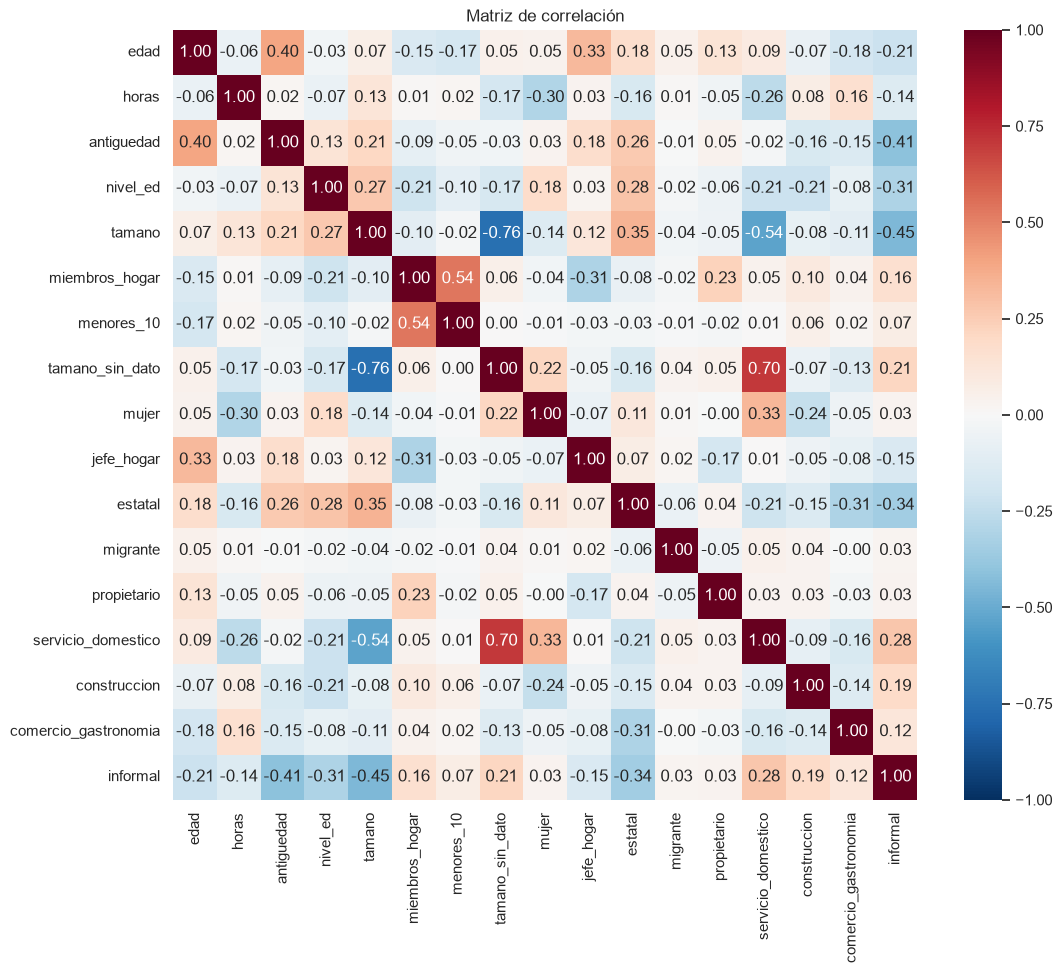

In [30]:
corr_matrix = datos[VARIABLES + ["informal"]].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0)
plt.title("Matriz de correlación")
plt.show()

In [31]:
# Correlación de cada variable con la variable objetivo, ordenada por fuerza
corr_matrix["informal"].drop("informal").sort_values(key=abs, ascending=False).round(2).to_frame()

,informal
tamano,-0.45
antiguedad,-0.41
estatal,-0.34
nivel_ed,-0.31
servicio_domestico,0.28
edad,-0.21
tamano_sin_dato,0.21
construccion,0.19
miembros_hogar,0.16
jefe_hogar,-0.15


Usamos la escala de la U4: **0 a 0,25** sin relación lineal, **0,25 a 0,50** débil, **0,50 a 0,75** moderada, **0,75 a 1** fuerte.

- Ninguna variable tiene una relación **fuerte** ni **moderada** con la informalidad. Las más importantes son el **tamaño del establecimiento (-0,45)**, la **antigüedad (-0,41)**, trabajar en el **Estado (-0,36)**, el **nivel educativo (-0,31)** y el **servicio doméstico (0,28)**, todas en el rango de relación **débil**. El signo negativo indica que a más tamaño, antigüedad o educación, menos informalidad.
- `tamano` y `tamano_sin_dato` están muy correlacionadas entre sí (-0,76) porque una se construyó a partir de la otra: cuando no hay dato, `tamano` vale 0.
- Las variables del hogar (miembros, menores, ser propietario), el sexo y haber nacido en otro país prácticamente **no tienen relación lineal** (menos de 0,25).
- Que ninguna variable sola sea determinante es justamente la razón para usar un modelo que combine **todas** a la vez.
- **Correlación no es causalidad:** que el tamaño de la empresa se relacione con la informalidad no prueba que una cosa cause la otra (por ejemplo, las empresas chicas pueden tener menos capacidad de afrontar las cargas sociales).

## 4.4 Serie de tiempo: tasa de informalidad por trimestre

Para la serie usamos **todas las filas** (antes de quitar las personas repetidas), porque en cada trimestre la muestra es distinta.

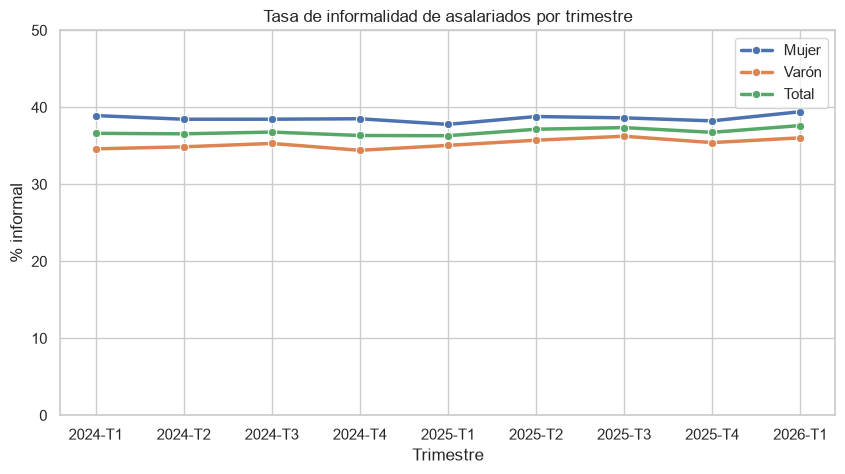

sexo,Mujer,Total,Varón
periodo,,,
2024-T1,38.90,36.60,34.60
2024-T2,38.40,36.60,34.90
2024-T3,38.40,36.80,35.30
2024-T4,38.50,36.30,34.40
2025-T1,37.80,36.30,35.00
2025-T2,38.80,37.10,35.70
2025-T3,38.60,37.40,36.20
2025-T4,38.20,36.70,35.40
2026-T1,39.40,37.60,36.00


In [32]:
serie = (
    datos.groupby(["periodo", "sexo"], as_index=False)
    .agg(tasa_informal=("informal", "mean"))
)
serie["tasa_informal"] = serie["tasa_informal"] * 100

serie_total = datos.groupby("periodo", as_index=False).agg(tasa_informal=("informal", "mean"))
serie_total["tasa_informal"] = serie_total["tasa_informal"] * 100
serie_total["sexo"] = "Total"

serie = pd.concat([serie, serie_total], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.lineplot(data=serie, x="periodo", y="tasa_informal", hue="sexo", marker="o", linewidth=2.5)
plt.ylim(0, 50)
plt.title("Tasa de informalidad de asalariados por trimestre")
plt.xlabel("Trimestre")
plt.ylabel("% informal")
plt.legend(title="")
plt.show()

serie.pivot(index="periodo", columns="sexo", values="tasa_informal").round(1)

La tasa se mantiene **estable** a lo largo de los nueve trimestres, entre 2024 y 2026 (el eje arranca en 0 para no exagerar diferencias de uno o dos puntos). Las variaciones entre trimestres son pequeñas y pueden ser simple variación de la muestra; lo que sí muestra la serie es que **el problema es persistente** y que las mujeres tienen una tasa algo mayor en todo el período.

---
# 5. Split: separar entrenamiento y prueba

## 5.1 Una fila por persona

Como explicamos en el paso 2.4, para el modelo nos quedamos con **una sola observación por persona** (la del trimestre más reciente), con `drop_duplicates`.

In [33]:
datos_modelo = (
    datos.sort_values(["ANO4", "TRIMESTRE"])
    .drop_duplicates(subset="id_persona", keep="last")
    .reset_index(drop=True)
)
print(f"Filas antes:   {len(datos):,}")
print(f"Personas únicas para el modelo: {len(datos_modelo):,}")
print(f"% informal: {datos_modelo['informal'].mean():.1%}")

Filas antes:   132,368
Personas únicas para el modelo: 71,222
% informal: 40.8%


La proporción de informales sube un poco (de 37 % a casi 41 %) porque, entre las personas que aparecen en dos trimestres, hay proporcionalmente más formales; al quedarnos con una fila por persona, esas personas dejan de contarse dos veces.

## 5.2 Definir X e y, y separar 80/20

- **X:** 13 variables (5 numéricas u ordinales y 8 binarias).
- **y:** `informal` (1 = sin descuento jubilatorio, 0 = registrado).

**Dejamos afuera del modelo las tres variables del hogar** que sumamos con el merge (`miembros_hogar`, `menores_10`, `propietario`). En el EDA vimos que casi no tienen relación con la informalidad (correlación menor a 0,2). En k-NN eso es un problema: **todas las columnas cuentan en la distancia**, así que una variable que no aporta información igual cambia quiénes son los vecinos y mete ruido. Lo comprobamos con validación cruzada sobre train: sin esas tres variables el accuracy de validación (k = 31) sube de 80,3 % a 81,2 %. Agregar variables no siempre mejora un modelo de k-NN.

Usamos `stratify=y` para que train y test tengan **la misma proporción de informales**. El conjunto de test **no se toca** hasta el final.

In [34]:
# Variables independientes o predictoras X
X = datos_modelo[VARIABLES_MODELO]

# Variable objetivo o variable respuesta y
y = datos_modelo["informal"]

# Split 80/20 estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)

Train: (56977, 13)  Test: (14245, 13)


,train,test
informal,,
0,0.59,0.59
1,0.41,0.41


## 5.3 Completar la antigüedad faltante con la mediana de train

Calculamos la mediana **solo con train** y la usamos para completar train y test. Si la calculáramos con todos los datos, estaríamos usando información de test (el mismo motivo por el que el `StandardScaler` va dentro del Pipeline).

In [35]:
mediana_antiguedad = X_train["antiguedad"].median()
print(f"Mediana de antigüedad en train: {mediana_antiguedad}")

X_train = X_train.fillna({"antiguedad": mediana_antiguedad})
X_test = X_test.fillna({"antiguedad": mediana_antiguedad})

print("Nulos en X_train:", X_train.isna().sum().sum(), "| Nulos en X_test:", X_test.isna().sum().sum())

Mediana de antigüedad en train: 5.0
Nulos en X_train: 0 | Nulos en X_test: 0


---
# 6. Modelo

## 6.1 El baseline: predecir siempre la clase más frecuente

`DummyClassifier` predice siempre "formal". Cualquier modelo que valga la pena tiene que superarlo.

In [36]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

acc_baseline = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline (siempre {baseline.predict(X_test)[0]} = formal): {acc_baseline:.1%}")

Baseline (siempre 0 = formal): 59.2%


## 6.2 k-NN con k = 5: sin escalar y con escalado

k-NN clasifica a una persona buscando a las **k personas más parecidas** de train y devolviendo **la clase más votada**.

Como mide **distancias**, la escala importa: la edad va de 14 a 100 y las variables binarias de 0 a 1. **Sin escalar, la edad dominaría la distancia**. `StandardScaler` lleva cada columna a media 0 y desvío 1, y con un `Pipeline` nos aseguramos de que el scaler se ajuste **solo con train**.

In [37]:
# k-NN sin escalar
knn_crudo = KNeighborsClassifier(n_neighbors=5)
knn_crudo.fit(X_train, y_train)
acc_crudo = accuracy_score(y_test, knn_crudo.predict(X_test))

# k-NN escalado con Pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
pipe.fit(X_train, y_train)
acc_escalado = accuracy_score(y_test, pipe.predict(X_test))

print(f"Baseline:              {acc_baseline:.1%}")
print(f"k-NN k=5 sin escalar:  {acc_crudo:.1%}")
print(f"k-NN k=5 escalado:     {acc_escalado:.1%}")

Baseline:              59.2%
k-NN k=5 sin escalar:  78.3%
k-NN k=5 escalado:     79.6%


Para ver qué hace el `StandardScaler`, aplicamos el scaler ya entrenado dentro del Pipeline a los datos de train y miramos los mínimos y máximos de cada variable, antes y después de escalar:

In [38]:
# Aplicar el scaler entrenado dentro del pipeline
X_train_scaled = pd.DataFrame(
    pipe.named_steps["scaler"].transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

pd.DataFrame({
    "min original": X_train.min(),
    "max original": X_train.max(),
    "min escalado": X_train_scaled.min(),
    "max escalado": X_train_scaled.max(),
}).round(2)

,min original,max original,min escalado,max escalado
edad,14.00,100.00,-2.01,4.69
horas,0.00,98.00,-2.08,3.86
antiguedad,1.00,6.00,-3.45,0.77
nivel_ed,0.00,6.00,-3.11,1.31
tamano,0.00,3.00,-1.62,1.18
tamano_sin_dato,0.00,1.00,-0.46,2.16
mujer,0.00,1.00,-0.94,1.06
jefe_hogar,0.00,1.00,-0.94,1.06
estatal,0.00,1.00,-0.61,1.65
migrante,0.00,1.00,-0.18,5.67


Antes de escalar, la edad iba de 14 a 100 y las horas de 0 a 98, mientras que las variables 0/1 solo podían moverse una unidad. Después de escalar, **todas quedan centradas en 0 y medidas en desvíos**, así que ninguna domina la distancia por el solo hecho de tener números más grandes.

Escalar mejora el modelo: con todas las variables en la misma escala, la distancia tiene en cuenta a todas por igual y no solo a la edad y las horas.

> Esta comparación sobre test es solo ilustrativa. **El valor de k lo elegimos con validación cruzada**, sin mirar el test.

---
# 7. Entrenar: elegir k con validación cruzada

## 7.1 Validación cruzada para k = 5

Partimos train en 5 partes (`StratifiedKFold`, que mantiene la proporción de informales en cada parte) y entrenamos 5 veces, validando cada vez con una parte distinta.

In [39]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

scores = cross_val_score(pipe, X_train, y_train, cv=kfold, scoring="accuracy")

print("Accuracy de cada ronda:", scores.round(3))
print(f"Promedio: {scores.mean():.1%} ± {scores.std():.1%}")

Accuracy de cada ronda: [0.8   0.793 0.796 0.8   0.796]
Promedio: 79.7% ± 0.3%


## 7.2 GridSearchCV sobre el Pipeline

Probamos distintos valores de **k** y las dos formas de votar: todos los vecinos valen lo mismo (`uniform`) o los más cercanos pesan más (`distance`). Para un hiperparámetro de un paso del Pipeline se usa `nombre_del_paso__parametro`.

In [40]:
grilla = {
    "knn__n_neighbors": [1, 5, 15, 31, 51, 101, 201],
    "knn__weights": ["uniform", "distance"],
}

busqueda = GridSearchCV(pipe, grilla, cv=kfold, scoring="accuracy")
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"Accuracy de validación:  {busqueda.best_score_:.1%}")

Mejores hiperparámetros: {'knn__n_neighbors': 31, 'knn__weights': 'uniform'}
Accuracy de validación:  81.2%


In [41]:
# Resultados de la validación cruzada
res = pd.DataFrame(busqueda.cv_results_)
res = res[["param_knn__n_neighbors", "param_knn__weights", "mean_test_score", "std_test_score"]]
res = res.rename(columns={"param_knn__n_neighbors": "k", "param_knn__weights": "weights",
                          "mean_test_score": "accuracy_validacion", "std_test_score": "desvio"})
res["k"] = res["k"].astype(int)

# Mostramos accuracy y desvío en porcentaje para que se lean mejor
tabla_res = res.copy()
tabla_res["accuracy_validacion"] = (tabla_res["accuracy_validacion"] * 100).round(2)
tabla_res["desvio"] = (tabla_res["desvio"] * 100).round(2)
tabla_res.sort_values("accuracy_validacion", ascending=False).head(6)

,k,weights,accuracy_validacion,desvio
6,31,uniform,81.17,0.37
4,15,uniform,81.04,0.24
8,51,uniform,80.99,0.28
10,101,uniform,80.58,0.28
12,201,uniform,79.93,0.44
7,31,distance,79.89,0.36


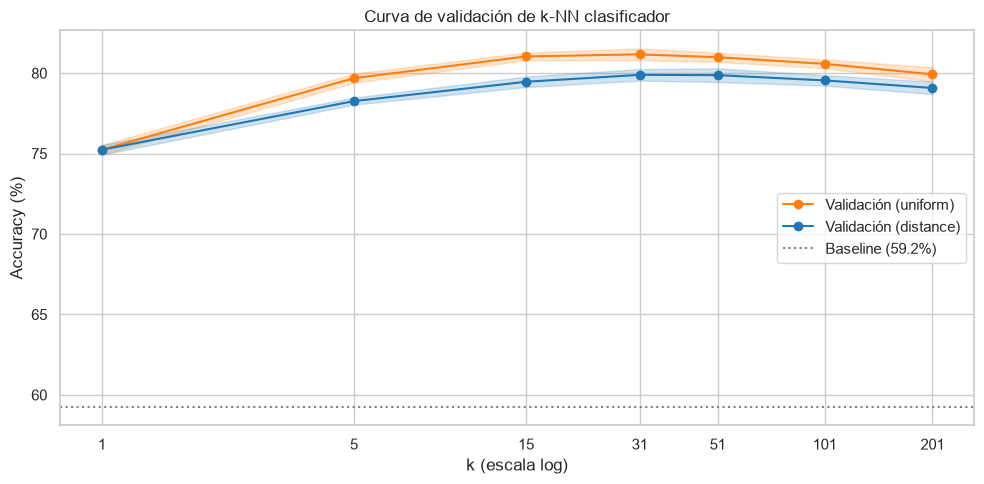

In [42]:
# Curva de validación
fig, ax = plt.subplots(figsize=(10, 5))

for w, color in [("uniform", "tab:orange"), ("distance", "tab:blue")]:
    r = res[res["weights"] == w]
    media = r["accuracy_validacion"] * 100
    desvio = r["desvio"] * 100
    ax.plot(r["k"], media, marker="o", color=color, label=f"Validación ({w})")
    ax.fill_between(r["k"], media - desvio, media + desvio, color=color, alpha=0.2)

ax.axhline(acc_baseline * 100, color="gray", linestyle=":", label=f"Baseline ({acc_baseline:.1%})")
ax.set_xscale("log")
ax.set_xticks(grilla["knn__n_neighbors"])
ax.set_xticklabels(grilla["knn__n_neighbors"])
ax.set_xlabel("k (escala log)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Curva de validación de k-NN clasificador")
ax.legend()
plt.tight_layout()
plt.show()

**Cómo leer la curva:**

- Con **k = 1** el accuracy es el más bajo: el modelo copia a una sola persona parecida (**sobreajuste**).
- A medida que k crece el modelo mejora, hasta que la curva **se aplana**: desde cierto k las diferencias son menores que el desvío entre rondas.
- Todos los modelos con k ≥ 5 están muy por encima del baseline.
- `GridSearchCV` ya reentrenó el mejor modelo con **todo train** (`refit=True` por defecto).

---
# 8. Predecir

Ahora sí, **una sola vez**, usamos el conjunto de test.

In [43]:
mejor_knn = busqueda.best_estimator_
y_pred = mejor_knn.predict(X_test)

y_pred[:10]

array([1, 1, 1, 0, 0, 1, 0, 1, 1, 0])

## 8.1 Una persona de test y sus vecinos: ¿cómo votaron?

Igual que con los diamantes, miramos a una persona de test y a sus k vecinos más parecidos de train. Como el modelo está en un Pipeline, primero escalamos con el scaler ya ajustado y después le pedimos los vecinos al k-NN.

In [44]:
i = 0
persona = X_test.iloc[[i]]

persona_escalada = mejor_knn.named_steps["scaler"].transform(persona)
distancias, posiciones = mejor_knn.named_steps["knn"].kneighbors(persona_escalada)

vecinos = X_train.iloc[posiciones[0]].copy()
vecinos["informal"] = y_train.iloc[posiciones[0]].values

print(f"Persona de test: real = {y_test.iloc[i]} | predicción = {y_pred[i]}")
print(f"De sus {len(vecinos)} vecinos, {vecinos['informal'].sum()} son informales")
persona

Persona de test: real = 1 | predicción = 1
De sus 31 vecinos, 22 son informales


,edad,horas,antiguedad,nivel_ed,tamano,tamano_sin_dato,mujer,jefe_hogar,estatal,migrante,servicio_domestico,construccion,comercio_gastronomia
29690,35,25.00,5.00,4,0,1,1,0,0,0,1,0,0


In [45]:
vecinos.head(10)

,edad,horas,antiguedad,nivel_ed,tamano,tamano_sin_dato,mujer,jefe_hogar,estatal,migrante,servicio_domestico,construccion,comercio_gastronomia,informal
40386,35,25.00,5.00,4,0,1,1,0,0,0,1,0,0,1
57575,35,25.00,5.00,4,0,1,1,0,0,0,1,0,0,1
52467,35,25.00,5.00,4,0,1,1,0,0,0,1,0,0,1
25712,35,24.00,5.00,4,0,1,1,0,0,0,1,0,0,0
17575,34,25.00,5.00,4,0,1,1,0,0,0,1,0,0,1
44026,34,25.00,5.00,4,0,1,1,0,0,0,1,0,0,1
21125,36,25.00,5.00,4,0,1,1,0,0,0,1,0,0,0
11711,34,24.00,5.00,4,0,1,1,0,0,0,1,0,0,1
69259,36,24.00,5.00,4,0,1,1,0,0,0,1,0,0,1
56460,36,24.00,5.00,4,0,1,1,0,0,0,1,0,0,1


## 8.2 Usar el modelo con perfiles nuevos

Así se usaría la herramienta en la práctica: cargamos los datos de una persona y el modelo predice si es probable que esté en la informalidad.

In [46]:
perfiles = pd.DataFrame([
    {"edad": 22, "horas": 30, "antiguedad": 3, "nivel_ed": 3, "tamano": 1,
     "tamano_sin_dato": 0, "mujer": 1, "jefe_hogar": 0, "estatal": 0, "migrante": 0,
     "servicio_domestico": 0, "construccion": 0, "comercio_gastronomia": 1},
    {"edad": 40, "horas": 45, "antiguedad": 6, "nivel_ed": 6, "tamano": 3,
     "tamano_sin_dato": 0, "mujer": 0, "jefe_hogar": 1, "estatal": 0, "migrante": 0,
     "servicio_domestico": 0, "construccion": 0, "comercio_gastronomia": 0},
], index=["Joven en un comercio chico", "Profesional en una empresa grande"])

perfiles["prediccion"] = mejor_knn.predict(perfiles[VARIABLES_MODELO])
perfiles["prediccion"] = perfiles["prediccion"].map({0: "Formal", 1: "Informal"})
perfiles[["edad", "nivel_ed", "tamano", "comercio_gastronomia", "prediccion"]]

,edad,nivel_ed,tamano,comercio_gastronomia,prediccion
Joven en un comercio chico,22,3,1,1,Informal
Profesional en una empresa grande,40,6,3,0,Formal


---
# 9. Evaluar

## 9.1 Accuracy contra el baseline

El **accuracy** indica qué proporción de las personas de test fue clasificada correctamente. Va de 0 a 1 (o de 0 % a 100 %). Es fácil de interpretar, pero **puede engañar cuando las clases están desbalanceadas**: en nuestro caso, el baseline que dice siempre "formal" ya acierta cerca del 59 % sin detectar a un solo informal.

In [47]:
acc_knn = accuracy_score(y_test, y_pred)
k_mejor = busqueda.best_params_["knn__n_neighbors"]

print("Accuracy / exactitud en test:")
print(f"Baseline (siempre formal):  {acc_baseline:.1%}")
print(f"k-NN k=5 sin escalar:       {acc_crudo:.1%}")
print(f"k-NN k=5 escalado:          {acc_escalado:.1%}")
print(f"Mejor k-NN (k={k_mejor}, CV):     {acc_knn:.1%}")
print(f"\nAciertos: {(y_test == y_pred).sum():,} de {len(y_test):,}")

Accuracy / exactitud en test:
Baseline (siempre formal):  59.2%
k-NN k=5 sin escalar:       78.3%
k-NN k=5 escalado:          79.6%
Mejor k-NN (k=31, CV):     80.9%

Aciertos: 11,529 de 14,245


## 9.2 Matriz de confusión

La matriz de confusión compara las **clases reales** (filas) con las **clases predichas** (columnas). A diferencia del accuracy, que da un único porcentaje global, muestra **cuántas personas se clasificaron bien en cada clase y con qué clase se confundieron las demás**.

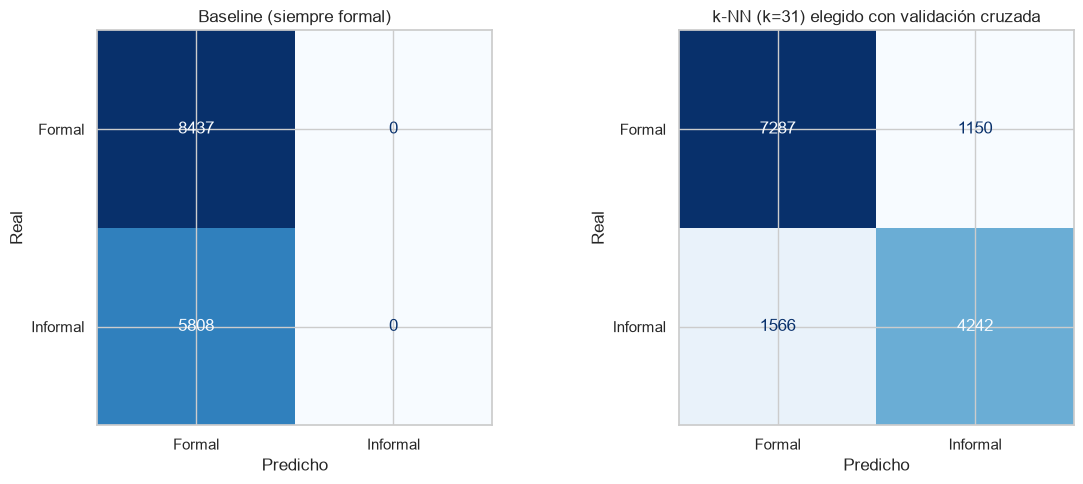

In [48]:
nombres = ["Formal", "Informal"]   # 0 y 1

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, baseline.predict(X_test), display_labels=nombres,
                                        ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Baseline (siempre formal)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=nombres,
                                        ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title(f"k-NN (k={k_mejor}) elegido con validación cruzada")
for ax in axes:
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

In [49]:
cm = confusion_matrix(y_test, y_pred)
pd.DataFrame(cm, index=["real Formal", "real Informal"], columns=["pred Formal", "pred Informal"])

,pred Formal,pred Informal
real Formal,7287,1150
real Informal,1566,4242


**Cómo leerla:**

- La celda **real Informal → predicho Formal** son los **falsos negativos**: informales que el modelo no detecta. Para una política de registración es **el error más grave**, porque esas personas quedarían fuera de la ayuda (como el tumor maligno que se predice benigno en el ejemplo de la U7).
- La celda **real Formal → predicho Informal** son los **falsos positivos**: personas registradas que el modelo marca como informales. Es un error menos grave: se le ofrecería un programa a alguien que no lo necesita.

## 9.3 Precision, Recall y F1-Score

Además del accuracy y la matriz de confusión, usamos precision, recall y F1 para ver con más detalle cómo le va al modelo **en cada clase**.

In [50]:
print("k-NN:")
print(classification_report(y_test, y_pred, target_names=nombres, digits=3))

k-NN:
              precision    recall  f1-score   support

      Formal      0.823     0.864     0.843      8437
    Informal      0.787     0.730     0.757      5808

    accuracy                          0.809     14245
   macro avg      0.805     0.797     0.800     14245
weighted avg      0.808     0.809     0.808     14245



- `accuracy`: aciertos / total de casos.
- `precision`: de los que el modelo predijo en esa clase, ¿cuántos eran de verdad? **TP / (TP + FP)**. En la matriz se mira **verticalmente** (por columna).
- `recall`: de los que eran de esa clase, ¿cuántos encontró? **TP / (TP + FN)**. En la matriz se mira **horizontalmente** (por fila).
- `f1-score`: el promedio armónico de precision y recall. Resume las dos en un número y **baja si alguna de las dos es mala**.
- `support`: cuántos casos reales hay de esa clase en test.
- `macro avg`: el promedio simple de las clases; todas pesan igual.
- `weighted avg`: el promedio ponderado por support; las clases grandes pesan más.

Para comparar, el mismo reporte del **baseline**:

In [51]:
print("Baseline (siempre formal):")
print(classification_report(y_test, baseline.predict(X_test), target_names=nombres, digits=3, zero_division=0))

Baseline (siempre formal):
              precision    recall  f1-score   support

      Formal      0.592     1.000     0.744      8437
    Informal      0.000     0.000     0.000      5808

    accuracy                          0.592     14245
   macro avg      0.296     0.500     0.372     14245
weighted avg      0.351     0.592     0.441     14245



### Accuracy y F1: qué cuenta cada una

- **Contra el baseline, las dos métricas cuentan historias muy distintas.** El baseline tiene un accuracy de 59 %, que no parece tan malo. Pero su **F1 de Informal es 0**, porque nunca predice esa clase, y su **F1 macro es apenas 0,37**. El F1 macro castiga a un modelo que ignora una clase; el accuracy no. El k-NN, en cambio, tiene un F1 macro de 0,80, muy cerca de su accuracy (0,81).
- **El F1 por clase muestra dónde le cuesta al modelo.** La clase Formal tiene un F1 más alto que la Informal. Para Informal, la **precision** (alrededor de 0,79) es mayor que el **recall** (alrededor de 0,73): cuando el modelo dice "informal" suele acertar, pero **se le escapa más de un cuarto de los informales**.
- En nuestro problema **los errores no pesan lo mismo**: dejar afuera a un informal (falso negativo) es más grave que incluir a un formal. Por eso, además del accuracy, miramos especialmente el **recall de Informal**, como en el ejemplo de los tumores de la U7.

## 9.4 ¿En qué se equivoca el modelo?

Primero miramos a los **informales que el modelo predijo como formales** (falsos negativos) y los comparamos con los informales que sí detectó, como hicimos con los diamantes Medios que el modelo predijo como Premium.

In [52]:
# Los informales que el modelo predijo como formales
error = (y_test == 1) & (y_pred == 0)
detectados = (y_test == 1) & (y_pred == 1)
print("Informales no detectados:", error.sum())
print("Informales detectados:   ", detectados.sum())

pd.DataFrame({
    "no detectados (promedio)": X_test[error].mean(),
    "detectados (promedio)": X_test[detectados].mean(),
}).round(2)

Informales no detectados: 1566
Informales detectados:    4242


,no detectados (promedio),detectados (promedio)
edad,40.33,35.76
horas,37.96,28.93
antiguedad,5.24,4.33
nivel_ed,4.25,3.48
tamano,1.88,0.87
tamano_sin_dato,0.13,0.34
mujer,0.41,0.52
jefe_hogar,0.49,0.34
estatal,0.23,0.02
migrante,0.05,0.03


Los informales que el modelo **no detecta** tienen un perfil muy distinto de los que sí detecta, y **se parecen a los trabajadores formales**:

- Son **mayores** (40 años de promedio contra 36), trabajan **más horas** (38 contra 29) y tienen **más antigüedad** (5,2 contra 4,3) y **más educación** (4,3 contra 3,5, cerca del secundario completo).
- Trabajan en **lugares más grandes** (tamaño promedio 1,9 contra 0,9) y casi nunca les falta el dato del tamaño (13 % contra 34 %).
- El **23 % trabaja en el Estado**, contra el 2 % de los informales detectados.
- Casi **ninguno está en servicio doméstico** (1 % contra 28 %) ni en la construcción (4 % contra 18 %).

Es decir, son informales con un **empleo "con apariencia formal"**: adultos, con jornada completa, años en el puesto, en empresas grandes o en el Estado. Sus vecinos más parecidos son mayoritariamente formales, y k-NN los clasifica igual. Con estas variables el modelo no tiene forma de distinguirlos (lo mismo que pasaba con los diamantes grandes pero baratos).

Después, con `groupby`, calculamos para cada grupo el accuracy y qué porcentaje de los informales reales detecta el modelo (recall).

In [53]:
test = datos_modelo.loc[X_test.index].copy()
test["prediccion"] = y_pred
test["acierto"] = (test["prediccion"] == test["informal"]).astype(int)
test["tamano_txt"] = test["tamano"].map(nombres_tam)

def errores_por(variable):
    tabla = test.groupby(variable, as_index=False).agg(personas=("acierto", "count"),
                                                      accuracy=("acierto", "mean"))
    detectados = (test[test["informal"] == 1]
                  .groupby(variable, as_index=False)
                  .agg(recall_informal=("prediccion", "mean")))
    tabla = pd.merge(tabla, detectados, on=variable, how="left")
    return tabla.round(2)

errores_por("tamano_txt")

,tamano_txt,personas,accuracy,recall_informal
0,6 a 40,4438,0.78,0.52
1,Hasta 5,2959,0.78,0.89
2,Más de 40,4331,0.88,0.17
3,Sin dato,2517,0.78,0.88


In [54]:
errores_por("estatal")

,estatal,personas,accuracy,recall_informal
0,0,10478,0.78,0.77
1,1,3767,0.89,0.23


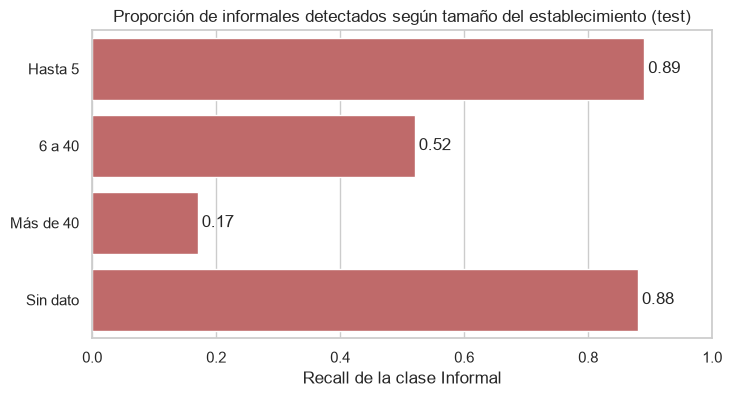

In [55]:
tabla_err = errores_por("tamano_txt")

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=tabla_err, x="recall_informal", y="tamano_txt",
                 order=["Hasta 5", "6 a 40", "Más de 40", "Sin dato"], color="indianred")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.xlim(0, 1)
plt.title("Proporción de informales detectados según tamaño del establecimiento (test)")
plt.xlabel("Recall de la clase Informal")
plt.ylabel("")
plt.show()

## 9.5 ¿Qué variables usa el modelo? Importancia por permutación

k-NN no tiene coeficientes ni pesos: solo mide distancias. Para saber en qué variables se apoya, usamos la **importancia por permutación** (`permutation_importance`): tomamos una variable, **mezclamos sus valores al azar** entre las personas de test y medimos **cuánto baja el accuracy**. Si el modelo depende de esa variable, al romperla se equivoca más; si no la usa, el accuracy casi no cambia. Repetimos la mezcla 5 veces por variable y promediamos.

Usamos test porque acá no elegimos nada del modelo: solo lo explicamos.


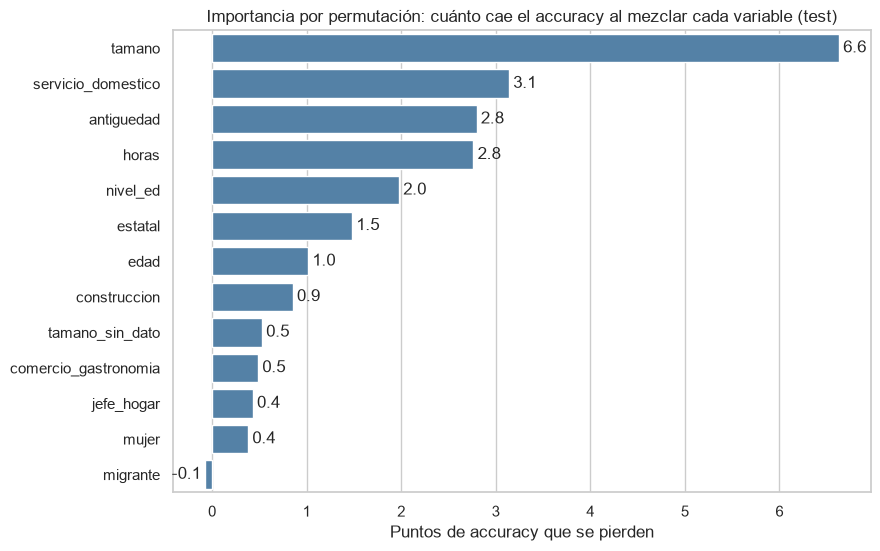

,variable,caida_accuracy,desvio
4,tamano,6.63,0.05
10,servicio_domestico,3.14,0.08
2,antiguedad,2.80,0.14
1,horas,2.76,0.13
3,nivel_ed,1.98,0.16
8,estatal,1.48,0.08
0,edad,1.02,0.08
11,construccion,0.85,0.07
5,tamano_sin_dato,0.53,0.05
12,comercio_gastronomia,0.49,0.07


In [56]:
imp = permutation_importance(mejor_knn, X_test, y_test, scoring="accuracy",
                             n_repeats=5, random_state=SEMILLA, n_jobs=-1)

importancias = pd.DataFrame({
    "variable": X_test.columns,
    "caida_accuracy": imp.importances_mean * 100,   # en puntos porcentuales
    "desvio": imp.importances_std * 100,
}).sort_values("caida_accuracy", ascending=False)

plt.figure(figsize=(9, 6))
ax = sns.barplot(data=importancias, x="caida_accuracy", y="variable", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
plt.title("Importancia por permutación: cuánto cae el accuracy al mezclar cada variable (test)")
plt.xlabel("Puntos de accuracy que se pierden")
plt.ylabel("")
plt.show()

importancias.round(2)

**Lo que muestra:**

- **El tamaño del establecimiento es, por lejos, la variable más importante:** al mezclarla, el accuracy cae más de 6 puntos, el doble que cualquier otra. Esto explica lo que vimos en 9.4: como el modelo se apoya tanto en el tamaño, a los informales que trabajan en lugares grandes los clasifica como formales.
- Le siguen **servicio doméstico, antigüedad y horas** (alrededor de 3 puntos cada una) y el **nivel educativo** (2 puntos).
- **No coincide del todo con la correlación del paso 4.3.** Las horas no estaban entre las variables más correlacionadas con la informalidad, pero el modelo las usa bastante: k-NN combina variables y aprovecha relaciones que no son lineales (por ejemplo, jornadas cortas junto con poca antigüedad). Al revés, trabajar en el **Estado** tenía una de las correlaciones más altas (-0,36), pero pesa solo 1,5 puntos: probablemente buena parte de esa información ya la aporta el tamaño, porque los empleos estatales suelen estar en establecimientos grandes.
- **Mujer, jefe de hogar y migrante casi no aportan** (menos de medio punto), y mezclar `migrante` ni siquiera baja el accuracy. Es lo mismo que pasaba con las variables del hogar: se podría probar sacarlas, pero eligiendo con validación cruzada sobre train, no mirando este resultado de test.
- Se confirma lo que veníamos viendo en el EDA: **dónde se trabaja** (tamaño, rama, sector) pesa más que **quién es la persona**.

---
# Conclusiones

### Qué aprendimos de los datos
- **La informalidad es masiva y persistente:** alrededor del **37 % de los asalariados** de la muestra no tiene descuento jubilatorio, y la tasa se mantuvo estable en los nueve trimestres, entre el 1T-2024 y el 1T-2026.
- **Dónde se trabaja pesa más que quién es la persona.** Las diferencias más grandes aparecen por **tamaño del establecimiento** (74 % de informalidad en lugares de hasta 5 personas contra 11 % en los de más de 40), por **rama** (78 % en servicio doméstico y 69 % en construcción) y por **sector** (11 % en el Estado contra 48 % fuera de él). La importancia por permutación lo confirma: el **tamaño del establecimiento** es, por lejos, la variable que más usa el modelo.
- **Terminar el secundario es un punto de quiebre:** la informalidad baja de alrededor del 58 % a 37 % al completarlo, y al 14 % con universitario completo.
- **Los jóvenes de 14 a 24 años son los más expuestos (68 %)**, seguidos por los mayores de 65 (46 %). Hay brechas regionales: Cuyo y NOA superan el 43 %, la Patagonia está en 21 %.
- Las variables del **hogar** que sumamos con el merge (miembros, menores, vivienda propia) casi no tienen relación con la informalidad. Por eso las **dejamos afuera del modelo**: en k-NN una variable que no aporta igual cuenta en la distancia y mete ruido. Sacarlas subió el accuracy de validación de 80,3 % a 81,2 %.

### Qué tan bien funciona el modelo
- El mejor modelo, elegido con validación cruzada sin mirar el test, fue **k-NN con k = 31** (`weights="uniform"`), con 13 variables. Entre k = 15 y k = 51 los resultados son prácticamente iguales.
- En test logra **80,9 % de accuracy contra 59,2 % del baseline**, que predice siempre "formal" y no detecta a ningún informal. El accuracy de validación (81,2 %) y el de test son casi iguales: la estimación es confiable.
- **Sumar años ayudó, pero poco:** pasar de 4 a 9 trimestres (de 39.639 a 71.222 personas) subió el accuracy de validación de 80,7 % a 81,2 %. Con k-NN el límite lo ponen las variables más que la cantidad de datos.
- **Escalar ayudó:** con k = 5, el accuracy pasó de 78,3 % sin escalar a 79,6 % con el `StandardScaler` en el Pipeline.
- **k = 1 sobreajusta:** es el peor valor en la curva de validación (alrededor de 75,2 %).
- **Detecta al 73 % de los informales** (recall), y de las personas que marca como informales, **el 79 % efectivamente lo es** (precision).
- **El F1 confirma la mejora frente al baseline:** el F1 macro del k-NN es 0,80, contra 0,37 del baseline, que tiene F1 = 0 en la clase Informal porque nunca la predice. El accuracy del baseline (59 %) escondía ese problema.

### En qué se equivoca
- El error más costoso para la política es el **falso negativo**: **1.566 informales que el modelo clasifica como formales** (de 5.808 en test), que quedarían fuera de la ayuda. Los falsos positivos son menos (1.150).
- Los informales no detectados son, en promedio, **mayores, con jornada completa, más antigüedad y más educación** que los detectados: se parecen a los formales.
- Los errores se concentran en la **informalidad "escondida"**: trabajadores no registrados en **establecimientos de más de 40 personas** (solo detecta al 17 %) y en el **Estado** (23 %). Son, por ejemplo, contratados precarios que en todo lo demás se parecen a los formales: sus vecinos más cercanos son formales y el modelo los clasifica igual.
- En cambio, en lugares chicos o cuando no se sabe el tamaño del establecimiento detecta a más del 85 % de los informales.

### Qué le agregaríamos para mejorarlo
1. **Más variables del trabajo:** si el empleo tiene fecha de finalización (contratos temporales), la calificación de la tarea, si tiene más de un empleo, y la rama completa en lugar de solo tres grupos.
2. **Incluir la región y el resto de las ramas** como variables del modelo (hoy solo están en el EDA), con una codificación que permita usar categorías sin orden.
3. **Priorizar el recall de los informales**: como dejar afuera a un informal es peor que incluir a un formal, convendría elegir k con una métrica que premie detectarlos (por ejemplo `scoring="recall"` o `"f1"` en `GridSearchCV`) y no solo con el accuracy.
4. **Más años no alcanza:** pasar de 4 a 9 trimestres mejoró solo medio punto. Para dar un salto hacen falta variables nuevas (punto 1), no más filas.
5. **Comparar con otros modelos**, como la regresión logística o los árboles de decisión.
6. Tener presente que la EPH es **urbana** y que los datos son **declarados** por los encuestados: el modelo no representa a la población rural.

### Cierre
Con datos básicos y fáciles de relevar, el modelo identifica a 7 de cada 10 trabajadores informales y supera claramente al baseline. Como herramienta de **priorización** sirve sobre todo para los perfiles más típicos (trabajo en casas particulares, construcción, comercio y gastronomía en lugares chicos, jóvenes con poca antigüedad). Para la informalidad "escondida" en el Estado y en empresas grandes el modelo no alcanza: ahí hacen falta otras herramientas, como el cruce de registros administrativos o las inspecciones.